# 11 — ML Model Development

**Goal:** build the leakage-safe target and feature set (including new
interaction/regime-shift features), remove collinearity rigorously, apply
a distribution transformation where it actually helps, split
chronologically with purge/embargo, train three candidate models, pick the
top 2 by validation performance, hyperparameter-tune those two specifically,
and make a final, evidence-based model choice.

**Important caveat:** this notebook's asset universe and history are small
and (depending on network availability) may be synthetic demo data with no
real predictive structure. Metrics here demonstrate the **methodology**,
not a claim of real trading edge — see notebook 13 for an honest discussion
of results.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'SPY' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['SPY', 'AAPL']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['BND', 'GLD', 'MSFT']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


## 1. Build features and target

In [2]:
from src.features.feature_pipeline import build_features_for_asset, FEATURE_SPEC
from src.models.targets import build_loss_event_target
from src.models.preprocessing import chronological_split
from src.models.train import train_model, time_series_cv_tune
from src.models.evaluate import classification_report
from src.config import CONFIG
from src.portfolio.analytics import portfolio_returns

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_returns = portfolio_returns(returns_panel, weights)
wealth = (1 + port_returns).cumprod()

prices_df = wealth.reset_index()
prices_df.columns = ["date", "adj_close"]
prices_df["volume"] = 1

feats = build_features_for_asset(prices_df).drop(columns=["beta_60d", "corr_market_60d", "volume_zscore_20d"])
target = build_loss_event_target(port_returns.reset_index(drop=True), horizon_days=CONFIG["ml"]["target_horizon_days"], loss_threshold=CONFIG["ml"]["loss_threshold"])

df = feats.copy()
df["target"] = target.values
df = df.dropna()
print(f"Features available: {[c for c in feats.columns if c != 'date']}")
print(f"\nRows after dropna: {len(df)}, positive (risk-event) rate: {df['target'].mean():.1%}")

Features available: ['ret_1d', 'ret_5d', 'ret_10d', 'ret_20d', 'ret_60d', 'vol_5d', 'vol_10d', 'vol_20d', 'vol_60d', 'vol_ratio_20_60', 'momentum_20d', 'ma_ratio_20_60', 'rsi_14', 'rolling_drawdown', 'momentum_vol_interaction']

Rows after dropna: 1938, positive (risk-event) rate: 2.6%


## 2. Time-series-aware split (never random shuffle)

A random train/test split (e.g. `sklearn.model_selection.train_test_split(shuffle=True)`) would scatter future observations into the training set and past observations into the test set — a model could then effectively "see the future" through autocorrelated neighboring rows. The chart below visualizes why a chronological, non-overlapping split (with purge/embargo gaps) is used instead: every fold's later portion strictly follows its earlier portion in time, matching how the model would actually be used in production (predict forward, never backward).

In [3]:
n = len(df)
train_end = df["date"].iloc[int(n * 0.55)]
validation_end = df["date"].iloc[int(n * 0.80)]

split = chronological_split(
    df, train_end=train_end, validation_end=validation_end,
    purge_days=CONFIG["ml"]["target_horizon_days"], embargo_days=CONFIG["ml"]["embargo_days"],
)
print(f"Train: {len(split.train)} rows ({split.train['date'].min().date()} -> {split.train['date'].max().date()})")
print(f"Validation: {len(split.validation)} rows ({split.validation['date'].min().date()} -> {split.validation['date'].max().date()})")
print(f"Test: {len(split.test)} rows ({split.test['date'].min().date()} -> {split.test['date'].max().date()})")

feature_cols = [c for c in df.columns if c not in ("date", "ticker", "target")]

Train: 1061 rows (2019-03-27 -> 2023-04-19)
Validation: 478 rows (2023-05-01 -> 2025-02-26)
Test: 385 rows (2025-03-10 -> 2026-08-28)


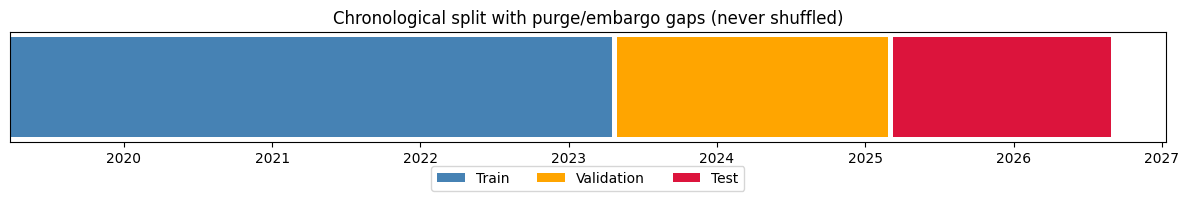

In [4]:
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.barh(0, (split.train["date"].max() - split.train["date"].min()).days, left=split.train["date"].min(), color="steelblue", label="Train")
ax.barh(0, (split.validation["date"].max() - split.validation["date"].min()).days, left=split.validation["date"].min(), color="orange", label="Validation")
ax.barh(0, (split.test["date"].max() - split.test["date"].min()).days, left=split.test["date"].min(), color="crimson", label="Test")
ax.set_yticks([])
ax.set_title("Chronological split with purge/embargo gaps (never shuffled)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

In [5]:
X_train, y_train = split.train[feature_cols], split.train["target"].astype(int)
X_val, y_val = split.validation[feature_cols], split.validation["target"].astype(int)
X_test, y_test = split.test[feature_cols], split.test["target"].astype(int)

## 3. Remove collinearity (variance filter -> iterative VIF)

The feature pipeline intentionally builds a broad, overlapping set (5 return horizons, 4 volatility horizons + a vol-ratio regime signal, momentum, an interaction term, RSI, drawdown, ...). Before training: drop near-constant features, then remove collinearity **iteratively by Variance Inflation Factor** rather than a single pairwise-correlation pass -- VIF catches a feature that's only reconstructible as a *combination* of several others, which a pairwise correlation check can miss. See `docs/PREPROCESSING_AND_FEATURE_SELECTION.md` §3 for the full rationale and `tests/test_feature_selection.py` for the automated leakage + correctness checks on this exact step. Everything below is fit on TRAIN only.

In [6]:
from src.models.feature_selection import (
    drop_low_variance_features, iterative_vif_removal,
    select_by_model_importance, variance_inflation_factors,
)

after_variance = drop_low_variance_features(X_train)
vifs_before = variance_inflation_factors(X_train[after_variance])
print("VIF before collinearity removal (VIF > 10 is a common red flag):")
print(vifs_before.round(1))

selected_cols = iterative_vif_removal(X_train[after_variance], vif_threshold=10.0)
print(f"\nFeatures: {len(feature_cols)} -> {len(after_variance)} (variance filter) -> {len(selected_cols)} (iterative VIF removal)")
print(f"Dropped as collinear: {sorted(set(after_variance) - set(selected_cols))}")

VIF before collinearity removal (VIF > 10 is a common red flag):
momentum_20d        58.5
ret_10d             11.1
ret_20d             10.5
rsi_14              10.4
ma_ratio_20_60       8.3
ret_60d              8.3
ret_5d               4.3
vol_20d              4.2
vol_ratio_20_60      3.1
rolling_drawdown     2.9
vol_10d              2.7
vol_5d               1.8
ret_1d               1.4
Name: VIF, dtype: float64

Features: 15 -> 13 (variance filter) -> 12 (iterative VIF removal)
Dropped as collinear: ['momentum_20d']


In [7]:
vifs_after = variance_inflation_factors(X_train[selected_cols])
print("VIF after collinearity removal -- every remaining feature should be well below 10:")
vifs_after.round(1)

VIF after collinearity removal -- every remaining feature should be well below 10:


ret_60d             8.2
ma_ratio_20_60      8.0
rsi_14              5.6
ret_10d             5.1
ret_20d             5.0
vol_20d             4.2
vol_ratio_20_60     3.1
rolling_drawdown    2.9
vol_10d             2.7
ret_5d              2.6
vol_5d              1.8
ret_1d              1.3
Name: VIF, dtype: float64

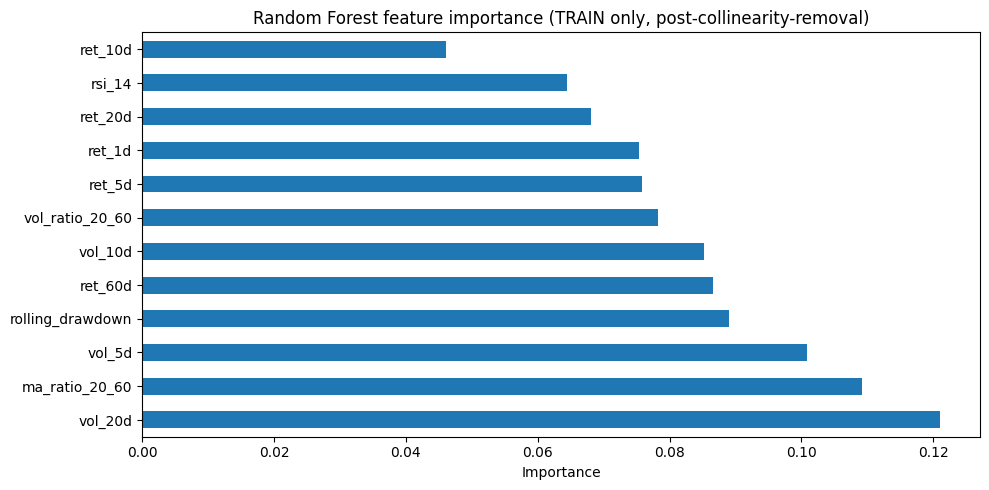


Final feature set used for training (12): ['ret_1d', 'ret_5d', 'ret_10d', 'ret_20d', 'ret_60d', 'vol_5d', 'vol_10d', 'vol_20d', 'vol_ratio_20_60', 'ma_ratio_20_60', 'rsi_14', 'rolling_drawdown']


In [8]:
if y_train.nunique() >= 2:
    importances = select_by_model_importance(X_train[selected_cols], y_train, random_seed=42)
    importances.plot(kind="barh", title="Random Forest feature importance (TRAIN only, post-collinearity-removal)")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

feature_cols = selected_cols
X_train, X_val, X_test = X_train[feature_cols], X_val[feature_cols], X_test[feature_cols]
print(f"\nFinal feature set used for training ({len(feature_cols)}): {feature_cols}")

## 4. Transformation: Yeo-Johnson for the skewed features

Volatility-based features are right-skewed by construction (a standard deviation can't be negative). Logistic Regression fits an additive effect in the feature's own scale, so heavy skew lets a few extreme days dominate the fitted coefficient. Box-Cox needs strictly positive input (ruled out -- several features here can be negative); Yeo-Johnson supports zero/negative values. Applied only where it helps -- see `build_preprocessing_pipeline`'s docstring.

In [9]:
skew_before = X_train.skew().sort_values(key=abs, ascending=False)
print("Feature skewness before any transformation (|skew| > 1 is notably non-Normal):")
print(skew_before.round(2))

Feature skewness before any transformation (|skew| > 1 is notably non-Normal):
rolling_drawdown   -0.94
vol_5d              0.45
ma_ratio_20_60     -0.23
vol_10d             0.21
vol_ratio_20_60    -0.20
rsi_14             -0.15
ret_60d            -0.14
vol_20d             0.12
ret_5d             -0.11
ret_10d            -0.10
ret_1d             -0.05
ret_20d            -0.04
dtype: float64


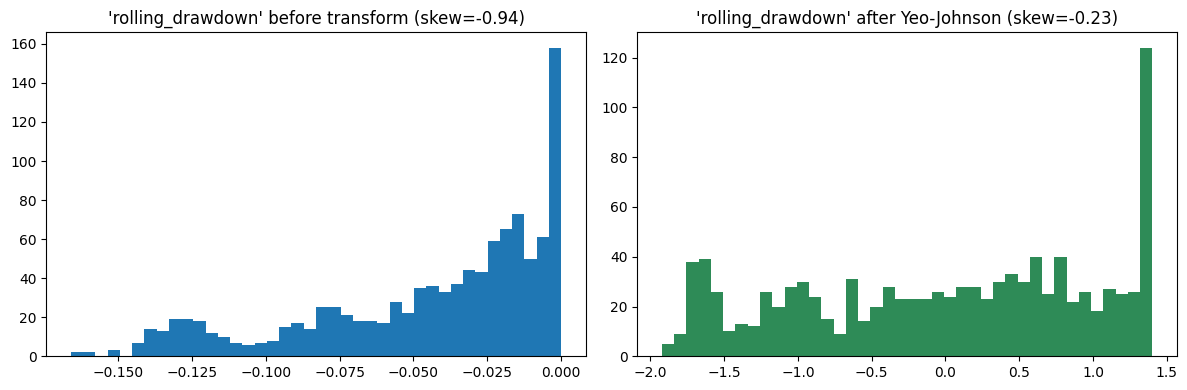

This transform is applied automatically inside train_model() for logistic_regression only (tree-based models are invariant to monotonic per-feature transforms, so it's skipped for them).


In [10]:
from sklearn.preprocessing import PowerTransformer

most_skewed = skew_before.index[0]
pt = PowerTransformer(method="yeo-johnson").fit(X_train[[most_skewed]])
transformed = pt.transform(X_train[[most_skewed]]).ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train[most_skewed].dropna(), bins=40)
axes[0].set_title(f"'{most_skewed}' before transform (skew={X_train[most_skewed].skew():.2f})")
axes[1].hist(transformed, bins=40, color="seagreen")
axes[1].set_title(f"'{most_skewed}' after Yeo-Johnson (skew={pd.Series(transformed).skew():.2f})")
plt.tight_layout()
plt.show()
print("This transform is applied automatically inside train_model() for logistic_regression only "
      "(tree-based models are invariant to monotonic per-feature transforms, so it's skipped for them).")

## 5. Train baseline models and compare on VALIDATION

Train all three candidates with default hyperparameters, then evaluate each on the VALIDATION split (never TEST at this stage) to identify the **top 2 performers** worth the cost of hyperparameter tuning. Class-imbalance handling is automatic and model-specific -- see `docs/MODEL_SELECTION_AND_EVALUATION.md` §1.

In [11]:
baseline_results = {}
if y_train.nunique() < 2:
    print("Only one class present in training data -- cannot train/compare models meaningfully in this run.")
else:
    for model_name in ["logistic_regression", "random_forest", "hist_gradient_boosting"]:
        trained = train_model(X_train, y_train, model_name, numeric_features=feature_cols)
        val_proba = trained.pipeline.predict_proba(X_val)[:, 1]
        val_pred = (val_proba >= 0.5).astype(int)
        report = classification_report(y_val, pd.Series(val_pred), pd.Series(val_proba))
        baseline_results[model_name] = {"trained": trained, **report}
        print(f"{model_name:22s}  val ROC-AUC={report['roc_auc']:.3f}  val PR-AUC={report['pr_auc']:.3f}  val recall={report['recall']:.2f}")

baseline_table = pd.DataFrame({k: {m: v for m, v in d.items() if m != "trained"} for k, d in baseline_results.items()}).T
baseline_table[["roc_auc", "pr_auc", "recall", "precision", "f1"]].round(3) if not baseline_table.empty else baseline_table

logistic_regression     val ROC-AUC=0.543  val PR-AUC=0.066  val recall=0.30


random_forest           val ROC-AUC=0.453  val PR-AUC=0.056  val recall=0.00


hist_gradient_boosting  val ROC-AUC=0.416  val PR-AUC=0.052  val recall=0.00


,roc_auc,pr_auc,recall,precision,f1
logistic_regression,0.543,0.066,0.304,0.064,0.106
random_forest,0.453,0.056,0.000,0.000,0.000
hist_gradient_boosting,0.416,0.052,0.000,0.000,0.000


In [12]:
if baseline_results:
    # Rank by validation ROC-AUC (threshold-independent -- see
    # docs/MODEL_SELECTION_AND_EVALUATION.md §2 for why this is the primary
    # ranking metric rather than accuracy or a single-threshold metric).
    ranked = baseline_table["roc_auc"].fillna(-1).sort_values(ascending=False)
    top_2_models = ranked.index[:2].tolist()
    print(f"Top 2 models by validation ROC-AUC: {top_2_models}")
else:
    top_2_models = []
    print("No models trained in this run (single-class training data) -- skipping selection/tuning.")

Top 2 models by validation ROC-AUC: ['logistic_regression', 'random_forest']


## 6. Hyperparameter tuning — top 2 models only (TRAIN+VALIDATION, time-aware CV)

Tuning every candidate model is wasted effort once two are already clearly ahead on validation performance. `time_series_cv_tune` uses `TimeSeriesSplit`, so every fold's validation indices come strictly after its training indices — the TEST set is never passed in here, preserving it for the final, one-time comparison in step 7.

In [13]:
PARAM_GRIDS = {
    "random_forest": {"n_estimators": [100, 300], "max_depth": [4, 6, 8]},
    "hist_gradient_boosting": {"max_iter": [100, 300], "max_depth": [3, 4, 6], "learning_rate": [0.03, 0.05, 0.1]},
    "logistic_regression": {"C": [0.01, 0.1, 1.0, 10.0]},
}

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

tuned_params = {}
for model_name in top_2_models:
    try:
        best_params, best_score = time_series_cv_tune(
            X_train_val, y_train_val, model_name, PARAM_GRIDS[model_name], n_splits=3,
        )
        tuned_params[model_name] = best_params
        print(f"{model_name}: best params={best_params}  (CV ROC-AUC={best_score:.3f})")
    except ValueError as e:
        print(f"{model_name}: tuning could not run ({e})")
        print("  -> Expected with a very rare positive class and few CV splits, not a bug. "
              "Falling back to default hyperparameters for this model.")
        tuned_params[model_name] = {}

logistic_regression: best params={'C': 10.0}  (CV ROC-AUC=0.577)


random_forest: best params={'max_depth': 4, 'n_estimators': 100}  (CV ROC-AUC=0.467)


## 7. Re-compare the tuned top-2 models and pick the final winner

Retrain each of the top 2 with its tuned hyperparameters (still on TRAIN only, same leakage-safe `Pipeline`), then compare them against each other one final time on VALIDATION to choose the model that goes into the registry. TEST is reserved for notebook 13's one-time, final held-out evaluation of the winner — not used here to avoid tuning/selecting based on it.

In [14]:
final_results = {}
for model_name in top_2_models:
    trained = train_model(X_train, y_train, model_name, numeric_features=feature_cols)
    # apply tuned hyperparameters on top of the leakage-safe pipeline
    if tuned_params.get(model_name):
        trained.pipeline.named_steps["model"].set_params(**tuned_params[model_name])
        trained.pipeline.fit(X_train, y_train)

    val_proba = trained.pipeline.predict_proba(X_val)[:, 1]
    val_pred = (val_proba >= 0.5).astype(int)
    report = classification_report(y_val, pd.Series(val_pred), pd.Series(val_proba))
    final_results[model_name] = {"trained": trained, **report}

if final_results:
    comparison = pd.DataFrame({m: {k: v for k, v in d.items() if k != "trained"} for m, d in final_results.items()}).T
    print("Tuned model comparison on VALIDATION:")
    display(comparison[["roc_auc", "pr_auc", "recall", "precision", "f1"]].round(3))

    winner_name = comparison["roc_auc"].fillna(-1).idxmax()
    winner = final_results[winner_name]["trained"]
    print(f"\nFinal selected model: {winner_name} (highest validation ROC-AUC={comparison.loc[winner_name, 'roc_auc']:.3f})")
else:
    winner_name, winner = None, None
    print("No comparison possible in this run (single-class training data).")

Tuned model comparison on VALIDATION:


,roc_auc,pr_auc,recall,precision,f1
logistic_regression,0.543,0.065,0.304,0.064,0.106
random_forest,0.427,0.049,0.000,0.000,0.000



Final selected model: logistic_regression (highest validation ROC-AUC=0.543)


## Takeaways

- Collinearity is now removed via iterative VIF (not a single pairwise-correlation pass), catching multi-feature redundancy a pairwise check would miss.
- The skewed volatility-based features go through a Yeo-Johnson transform automatically, but only for the model that actually benefits (Logistic Regression) -- tree models are left untouched.
- Every split is chronological with purge/embargo gaps -- never a random shuffle -- matching how the model would actually be used.
- Hyperparameter tuning is deliberately restricted to the top 2 baseline performers (by validation ROC-AUC), then those two are compared again after tuning to make the final selection -- TEST stays untouched until notebook 13's one-time final evaluation.
- See `docs/MODEL_SELECTION_AND_EVALUATION.md` for the full rationale behind choosing these three specific models and how each handles the rare-event class imbalance.
- Continue to **12 — Walk-Forward Backtesting** to see how a reoptimized strategy performs over time with realistic costs.